In [ ]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn.functional as F
from torchvision.models import resnet50, ResNet50_Weights

print("Imports successful!")
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

Imports successful!
Device: GPU


In [ ]:
!pip -q install --upgrade kaggle

import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass(
    "KGAT_6bde507ac8f26d8d08f36279e4d63819 "
)

!kaggle datasets download -d yashdogra/cats-and-dogs -p /content --unzip

KGAT_6bde507ac8f26d8d08f36279e4d63819 ··········
Dataset URL: https://www.kaggle.com/datasets/yashdogra/cats-and-dogs
License(s): apache-2.0
100% 756M/756M [00:07<00:00, 105MB/s] 



In [ ]:
from pathlib import Path
import pandas as pd

IMAGE_DIR = Path("/content/images")

# Cat breeds in this dataset
cat_breeds = {
    "Abyssinian",
    "Bengal",
    "Birman",
    "Bombay",
    "British_Shorthair",
    "Egyptian_Mau",
    "Maine_Coon",
    "Persian",
    "Ragdoll",
    "Russian_Blue",
    "Siamese",
    "Sphynx"
}

records = []

for img_path in IMAGE_DIR.rglob("*"):
    if not img_path.is_file():
        continue

    if img_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp"}:
        continue

    # Filename format: breed_number.jpg
    breed = img_path.stem.rsplit("_", 1)[0]

    if breed in cat_breeds:
        label = "cat"
    else:
        label = "dog"

    records.append({
        "path": str(img_path),
        "true_label": label
    })

df = pd.DataFrame(records)
df = df.drop_duplicates(subset="path").reset_index(drop=True)

print("Total images found:", len(df))
print("\nImages per class:")
print(df["true_label"].value_counts())
print("\nSample records:")
print(df.head())

Total images found: 7390

Images per class:
true_label
dog    4990
cat    2400
Name: count, dtype: int64

Sample records:
                                             path true_label
0                   /content/images/Sphynx_77.jpg        cat
1       /content/images/miniature_pinscher_76.jpg        dog
2            /content/images/japanese_chin_66.jpg        dog
3  /content/images/english_cocker_spaniel_162.jpg        dog
4       /content/images/British_Shorthair_145.jpg        cat


In [ ]:
if df.empty:
    raise ValueError(
        "No labeled images found. Check the dataset folders and filenames."
    )

cat_df = df[df["true_label"] == "cat"].head(50)
dog_df = df[df["true_label"] == "dog"].head(50)

sample_df = pd.concat([cat_df, dog_df], ignore_index=True)
sample_df = sample_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Images selected:", len(sample_df))
print(sample_df["true_label"].value_counts())

Images selected: 100
true_label
dog    50
cat    50
Name: count, dtype: int64


In [ ]:
weights = ResNet50_Weights.DEFAULT
preprocess = weights.transforms()

model = resnet50(weights=weights)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

categories = weights.meta["categories"]

print("ResNet50 loaded successfully!")
print("Device:", device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 171MB/s]


ResNet50 loaded successfully!
Device: cuda


In [ ]:
# Standard ImageNet-1K category indices (zero-based)
dog_ids = list(range(151, 269))
cat_ids = list(range(281, 286))

results_list = []

for _, row in sample_df.iterrows():
    try:
        image = Image.open(row["path"]).convert("RGB")
        input_tensor = preprocess(image).unsqueeze(0).to(device)

        with torch.no_grad():
            logits = model(input_tensor)
            probabilities = torch.softmax(logits, dim=1)[0]

        cat_score = probabilities[cat_ids].sum().item()
        dog_score = probabilities[dog_ids].sum().item()

        if cat_score >= dog_score:
            predicted_label = "cat"
            confidence = cat_score / max(cat_score + dog_score, 1e-12)
        else:
            predicted_label = "dog"
            confidence = dog_score / max(cat_score + dog_score, 1e-12)

        results_list.append({
            "path": row["path"],
            "true_label": row["true_label"],
            "predicted_label": predicted_label,
            "cat_score": cat_score,
            "dog_score": dog_score,
            "confidence": confidence,
            "correct": predicted_label == row["true_label"]
        })

    except Exception as e:
        print("Could not process:", row["path"], "|", e)

results = pd.DataFrame(results_list)

print("Predictions completed:", len(results))
print(results.head())

Predictions completed: 100
                                       path true_label predicted_label  \
0         /content/images/shiba_inu_178.jpg        dog             dog   
1  /content/images/scottish_terrier_197.jpg        dog             dog   
2           /content/images/havanese_91.jpg        dog             dog   
3            /content/images/Birman_149.jpg        cat             cat   
4            /content/images/Bombay_140.jpg        cat             cat   

   cat_score  dog_score  confidence  correct  
0   0.005355   0.205328    0.974581     True  
1   0.002677   0.477968    0.994430     True  
2   0.001374   0.664391    0.997937     True  
3   0.377673   0.069911    0.843804     True  
4   0.349041   0.094623    0.786724     True  


In [ ]:
if results.empty:
    raise ValueError("No predictions were generated.")

accuracy = results["correct"].mean()

print(f"Accuracy on selected images: {accuracy:.2%}")
print("\nPrediction counts:")
print(results["predicted_label"].value_counts())

print("\nCorrect predictions:", results["correct"].sum())
print("Incorrect predictions:", (~results["correct"]).sum())

Accuracy on selected images: 98.00%

Prediction counts:
predicted_label
dog    52
cat    48
Name: count, dtype: int64

Correct predictions: 98
Incorrect predictions: 2


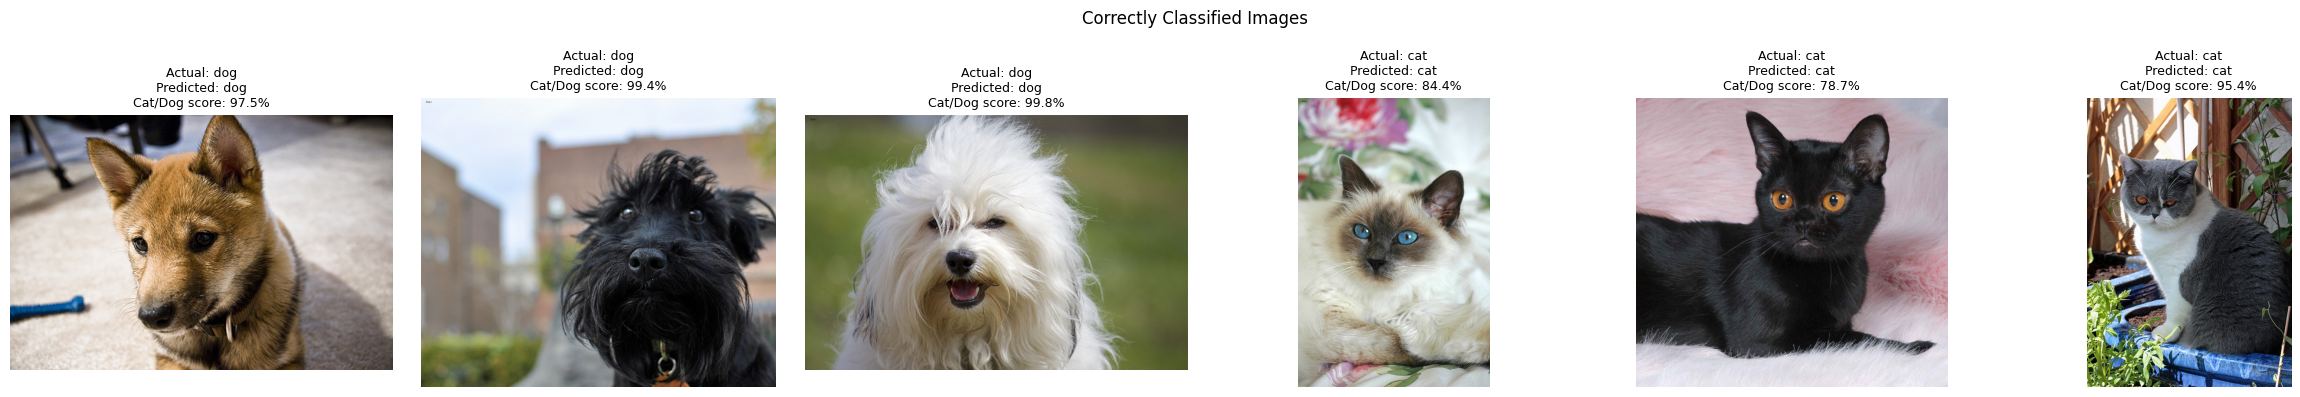

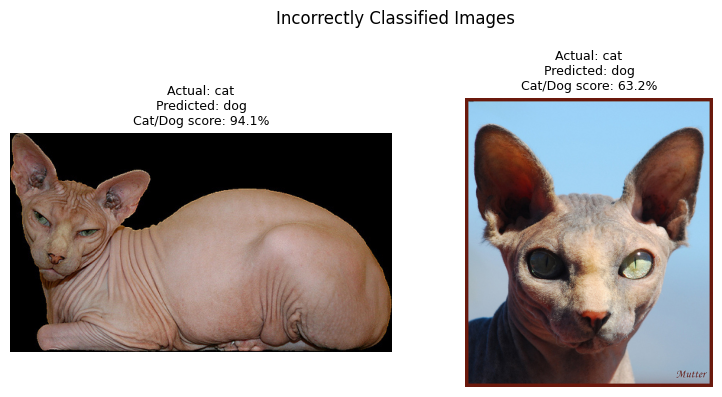

In [ ]:
def show_examples(data, title, n=6):
    if data.empty:
        print("No images available for:", title)
        return

    sample = data.head(n)

    fig, axes = plt.subplots(
        1, len(sample),
        figsize=(4 * len(sample), 4)
    )

    axes = np.atleast_1d(axes)

    for ax, (_, row) in zip(axes, sample.iterrows()):
        image = Image.open(row["path"]).convert("RGB")
        ax.imshow(image)

        ax.set_title(
            f"Actual: {row['true_label']}\n"
            f"Predicted: {row['predicted_label']}\n"
            f"Cat/Dog score: {row['confidence']:.1%}",
            fontsize=9
        )
        ax.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


correct_results = results[results["correct"]].reset_index(drop=True)
incorrect_results = results[~results["correct"]].reset_index(drop=True)

show_examples(correct_results, "Correctly Classified Images", n=6)
show_examples(incorrect_results, "Incorrectly Classified Images", n=6)

In [ ]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None

        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, inputs, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, image_tensor, class_ids):
        self.model.zero_grad(set_to_none=True)

        logits = self.model(image_tensor)
        probs = torch.softmax(logits, dim=1)[0]

        # Difference between the total cat and dog probabilities
        cat_score = probs[cat_ids].sum()
        dog_score = probs[dog_ids].sum()

        target_score = (
            cat_score - dog_score
            if class_ids == "cat"
            else dog_score - cat_score
        )

        target_score.backward()

        gradients = self.gradients
        activations = self.activations

        weights_cam = gradients.mean(dim=(2, 3), keepdim=True)

        cam = (weights_cam * activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)

        cam = F.interpolate(
            cam,
            size=image_tensor.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()
        cam = cam - cam.min()

        if cam.max() > 0:
            cam = cam / cam.max()

        return cam


gradcam = GradCAM(model, model.layer4[-1])
print("Grad-CAM initialized!")

Grad-CAM initialized!


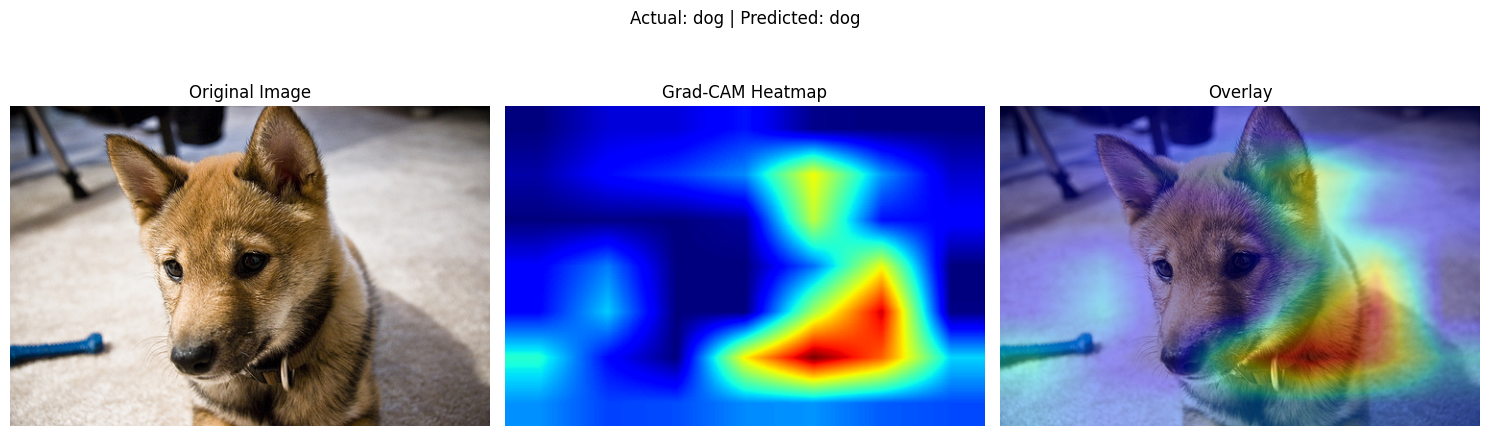

In [ ]:
def show_gradcam(row):
    image = Image.open(row["path"]).convert("RGB")
    input_tensor = preprocess(image).unsqueeze(0).to(device)

    model.eval()

    heatmap = gradcam.generate(
        input_tensor,
        row["predicted_label"]
    )

    heatmap_image = Image.fromarray(
        np.uint8(heatmap * 255)
    ).resize(image.size)

    heatmap_array = np.array(heatmap_image) / 255.0
    original = np.array(image)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(original)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_array, cmap="jet")
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(original)
    plt.imshow(
        heatmap_array,
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1
    )
    plt.title("Overlay")
    plt.axis("off")

    plt.suptitle(
        f"Actual: {row['true_label']} | "
        f"Predicted: {row['predicted_label']}"
    )
    plt.tight_layout()
    plt.show()


if not results.empty:
    show_gradcam(results.iloc[0])

In [ ]:
results.to_csv("/content/cats_dogs_predictions.csv", index=False)
print("Predictions saved to /content/cats_dogs_predictions.csv")

Predictions saved to /content/cats_dogs_predictions.csv
